# Movies: what makes a film a good investment?

This notebook investigates a dataset of 3,201 films released in the US,
with box office results, production budgets, release dates, genres and
audience ratings (vega-datasets, *movies*).

**Main question:** what makes a film a good investment?
I measure this as **return on investment (ROI) = US gross ÷ production budget**:
how many dollars a film earned at the US box office for every dollar it cost to make.

**Sub-questions**
1. Which genre groups give the best ROI?
2. Do adaptations (TV, plays, books, remakes) pay off better than original screenplays?
3. Do bigger budgets give a better ROI?
4. Do higher-rated films (IMDb) give a better ROI?

**What you will find:** a first look at the data, the cleaning steps
(including impossible release dates and suspicious gross figures),
group summaries, charts, answers to the questions above, and a data note
on where the data comes from and how far it can be trusted.

**Short answer:** thrillers/horror films and well-rated films earn back their budget most often, dramas least often. Cheap films only look better because of old films; for 1990-2009 budget size makes almost no difference.

## 0. Setup

In [70]:
# imports
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pandas.tseries.api import guess_datetime_format

from matplotlib.ticker import MultipleLocator

# data
movies_source = pd.read_csv("data/movies/movies.csv")
genres_source = pd.read_csv("data/movies/genre_groups.csv")
movies = movies_source.copy()
genres = genres_source.copy()

# display settings: plain numbers with thousands separators
pd.set_option("display.float_format", "{:,.2f}".format)

# seaborn settings
sns.set_theme(style="whitegrid", palette=["#404040"])  # dark grey for all charts

## 1. Understand the data

### 1.1 What is one row?

In [71]:
display(movies.sample(5, random_state=1))
display(len(movies))

,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
1751,Firestorm,"8,123,860.00","8,123,860.00",NaN,"19,000,000.00",Jan 09 1998,R,NaN,20th Century Fox,Original Screenplay,Action,Contemporary Fiction,NaN,NaN,4.40,"2,118.00"
909,Star Trek: Generations,"75,671,262.00","120,000,000.00",NaN,"38,000,000.00",Nov 18 1994,PG,NaN,Paramount Pictures,Based on TV,Adventure,Science Fiction,NaN,NaN,6.50,"26,465.00"
979,Trois,"1,161,843.00","1,161,843.00",NaN,"200,000.00",Feb 11 2000,NC-17,NaN,Rainforest Productions,Original Screenplay,Thriller/Suspense,Contemporary Fiction,NaN,NaN,3.30,360.00
329,Fled,"17,192,205.00","19,892,205.00",NaN,"30,000,000.00",Jul 19 1996,R,98.00,MGM,Original Screenplay,Action,Contemporary Fiction,NaN,14.00,4.90,"4,215.00"
1885,Ghost World,"6,217,849.00","8,764,007.00",NaN,"5,500,000.00",Jul 20 2001,R,NaN,MGM,Based on Comic/Graphic Novel,Comedy,Contemporary Fiction,Terry Zwigoff,92.00,7.70,"42,973.00"


3201

Each row is one film (3,201 in total). For every film the dataset holds:
- **Money:** US and worldwide gross, US DVD sales, production budget
- **Release info:** release date, distributor, MPAA rating, running time
- **Content:** major genre, creative type, source, director
- **Reception:** Rotten Tomatoes rating, IMDB rating and votes

- Columns I use: Production Budget, US Gross, Release Date, Major Genre, Source and IMDB Rating.

### 1.2 Size of the data

In [72]:
movies.shape

(3201, 16)

- The table has 3,201 rows and 16 columns.

### 1.3 Columns and data types

In [73]:
movies.info()

<class 'pandas.DataFrame'>
RangeIndex: 3201 entries, 0 to 3200
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Title                   3200 non-null   str    
 1   US Gross                3194 non-null   float64
 2   Worldwide Gross         3194 non-null   float64
 3   US DVD Sales            564 non-null    float64
 4   Production Budget       3200 non-null   float64
 5   Release Date            3201 non-null   str    
 6   MPAA Rating             2596 non-null   str    
 7   Running Time min        1209 non-null   float64
 8   Distributor             2969 non-null   str    
 9   Source                  2836 non-null   str    
 10  Major Genre             2926 non-null   str    
 11  Creative Type           2755 non-null   str    
 12  Director                1870 non-null   str    
 13  Rotten Tomatoes Rating  2321 non-null   float64
 14  IMDB Rating             2988 non-null   float64
 15

- `Release Date` is stored as text (`str`), but should be `datetime64` (converted in 2.1).
- `US DVD Sales` (564 of 3,201), `Running Time min` (1,209) and `Director` (1,870) are missing for many films (see section 3).
- The currency is not documented. `US Gross`, `MPAA Rating`, `US DVD Sales` and the English titles point to American data, so I assume US dollars.

### 1.4 First and last rows

In [74]:
display(movies.head())
display(movies.tail())


,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
0,The Land Girls,"146,083.00","146,083.00",NaN,"8,000,000.00",Jun 12 1998,R,NaN,Gramercy,NaN,NaN,NaN,NaN,NaN,6.10,"1,071.00"
1,"First Love, Last Rites","10,876.00","10,876.00",NaN,"300,000.00",Aug 07 1998,R,NaN,Strand,NaN,Drama,NaN,NaN,NaN,6.90,207.00
2,I Married a Strange Person,"203,134.00","203,134.00",NaN,"250,000.00",Aug 28 1998,NaN,NaN,Lionsgate,NaN,Comedy,NaN,NaN,NaN,6.80,865.00
3,Let's Talk About Sex,"373,615.00","373,615.00",NaN,"300,000.00",Sep 11 1998,NaN,NaN,Fine Line,NaN,Comedy,NaN,NaN,13.00,NaN,NaN
4,Slam,"1,009,819.00","1,087,521.00",NaN,"1,000,000.00",Oct 09 1998,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,NaN,62.00,3.40,165.00


,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
3196,Zack and Miri Make a Porno,"31,452,765.00","36,851,125.00","21,240,321.00","24,000,000.00",Oct 31 2008,R,101.00,Weinstein Co.,Original Screenplay,Comedy,Contemporary Fiction,Kevin Smith,65.00,7.00,"55,687.00"
3197,Zodiac,"33,080,084.00","83,080,084.00","20,983,030.00","85,000,000.00",Mar 02 2007,R,157.00,Paramount Pictures,Based on Book/Short Story,Thriller/Suspense,Dramatization,David Fincher,89.00,NaN,NaN
3198,Zoom,"11,989,328.00","12,506,188.00","6,679,409.00","35,000,000.00",Aug 11 2006,PG,NaN,Sony Pictures,Based on Comic/Graphic Novel,Adventure,Super Hero,Peter Hewitt,3.00,3.40,"7,424.00"
3199,The Legend of Zorro,"45,575,336.00","141,475,336.00",NaN,"80,000,000.00",Oct 28 2005,PG,129.00,Sony Pictures,Remake,Adventure,Historical Fiction,Martin Campbell,26.00,5.70,"21,161.00"
3200,The Mask of Zorro,"93,828,745.00","233,700,000.00",NaN,"65,000,000.00",Jul 17 1998,PG-13,136.00,Sony Pictures,Remake,Adventure,Historical Fiction,Martin Campbell,82.00,6.70,"4,789.00"


- `Release Date` is written as month, day, year, e.g. "Jun 12 1998" (`%b %d %Y`).
- Why are `US Gross` and `Worldwide Gross` identical for some films? Possible reasons: either the film had no release outside the US, or the worldwide figure is missing and the US value was copied in (checked in 2.3).

### 1.5 Number summary

In [75]:
movies.describe().round(1)

,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Running Time min,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
count,"3,194.00","3,194.00",564.00,"3,200.00","1,209.00","2,321.00","2,988.00","2,988.00"
mean,"44,002,085.20","85,343,400.10","34,901,546.80","31,069,171.40",110.20,54.30,6.30,"29,908.60"
std,"62,555,311.40","149,947,342.90","45,895,121.60","35,585,913.40",20.20,28.10,1.30,"44,937.60"
min,0.00,0.00,"618,454.00",218.00,46.00,1.00,1.40,18.00
25%,"5,493,221.20","8,031,285.20","9,906,210.80","6,575,000.00",95.00,30.00,5.60,"4,828.50"
50%,"22,019,465.50","31,168,926.50","20,331,557.50","20,000,000.00",107.00,55.00,6.40,"15,106.00"
75%,"56,091,761.50","97,283,797.00","37,794,215.80","42,000,000.00",121.00,80.00,7.20,"35,810.50"
max,"760,167,650.00","2,767,891,499.00","352,582,053.00","300,000,000.00",222.00,100.00,9.20,"519,541.00"


- `US Gross` and `Worldwide Gross` have a minimum value of \$0 (checked in 2.3).
- `US Gross` has a mean of about \$44M but a median of about \$22M. The mean is about twice the median, and the max is far above the 75th percentile. This suggests a few very high-grossing films pull the mean up (examined in section 7).
- `Production Budget` has a minimum value of \$218 (checked in 2.3).

### 1.6 First look at genre_groups

In [76]:
display(genres.shape)
display(genres)
genres.info()

(12, 2)

,Major Genre,Genre group
0,Drama,Drama
1,Comedy,Comedy & music
2,Romantic Comedy,Comedy & music
3,Black Comedy,Comedy & music
4,Musical,Comedy & music
5,Action,Action & adventure
6,Adventure,Action & adventure
7,Western,Action & adventure
8,Thriller/Suspense,Thriller & horror
9,Horror,Thriller & horror


<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   Major Genre  12 non-null     str  
 1   Genre group  12 non-null     str  
dtypes: str(2)
memory usage: 324.0 bytes


- The table has 12 rows and 2 columns; `Major Genre` and `Genre group`.
- All values stored as text(`str`) 

## 2. Clean the data  [task 2]

### 2.1 Release Date: convert to datetime
`Release Date` is stored as text, so sorting it sorts alphabetically (Apr, Aug, Dec ...), not by date.

In [77]:
by_date = movies.sort_values("Release Date", ascending=False)[["Title", "Release Date"]]
display(by_date.head())  # newest
display(by_date.tail())  # oldest

,Title,Release Date
2585,The Queen,Sep 30 2006
2317,MirrorMask,Sep 30 2005
1412,Capote,Sep 30 2005
1783,Serenity,Sep 30 2005
2401,Into the Blue,Sep 30 2005


,Title,Release Date
117,Bang,Apr 01 1996
106,"Bright Lights, Big City",Apr 01 1988
583,My Beautiful Laundrette,Apr 01 1986
266,Death Race 2000,Apr 01 1975
876,The Sound of Music,Apr 01 1965


In [78]:
guess_datetime_format(movies["Release Date"].iloc[0])

'%b %d %Y'

- Dates are written as `%b %d %Y`, e.g. "Jun 12 1998".
- We convert to `datetime64` to be able to sort the values correctly.
- Then we sort and display again.

In [79]:
# convert to datetime
movies["Release Date"] = pd.to_datetime(
    movies["Release Date"], errors="coerce", format="%b %d %Y"
)
# Show NaT count
display(movies["Release Date"].isna().sum())
# sort by release date and display newest and oldest
by_date = movies.sort_values("Release Date", ascending=False)[["Title", "Release Date"]]
display(by_date.head())  # newest
display(by_date.tail())  # oldest

np.int64(0)

,Title,Release Date
9,Duel in the Sun,2046-12-31
90,The Best Years of Our Lives,2046-11-21
16,Wilson,2044-08-01
382,A Guy Named Joe,2043-12-24
221,Cat People,2042-11-16


,Title,Release Date
51,Alexander's Ragtime Band,1937-12-31
951,It Happened One Night,1933-12-31
572,Mata Hari,1930-12-31
404,Hell's Angels,1929-12-31
114,The Broadway Melody,1928-12-31


- We can now see release dates in the future, which is impossible.
- The datasets last commit is 16 June 2020, so it cannot contain real release dates after that date.
- Next we count the films with impossible release dates (after 2020), and also look for strange dates before 2020.

### 2.2 Release Date: impossible years and Dec 31 placeholders

In [80]:
# films with a release date after the last commit (16 June 2020)
future_date = movies.loc[
    movies["Release Date"] > "2020-06-16", ["Title", "Release Date"]
]
display(future_date)
# count them
print(f"Count: {len(future_date)}")


,Title,Release Date
9,Duel in the Sun,2046-12-31
15,Over the Hill to the Poorhouse,2020-09-17
16,Wilson,2044-08-01
33,42nd Street,2033-03-09
85,Ben-Hur,2025-12-30
90,The Best Years of Our Lives,2046-11-21
102,The Big Parade,2025-01-01
174,"Charge of the Light Brigade, The",2036-10-20
221,Cat People,2042-11-16
337,Fantasia,2040-11-13


Count: 19


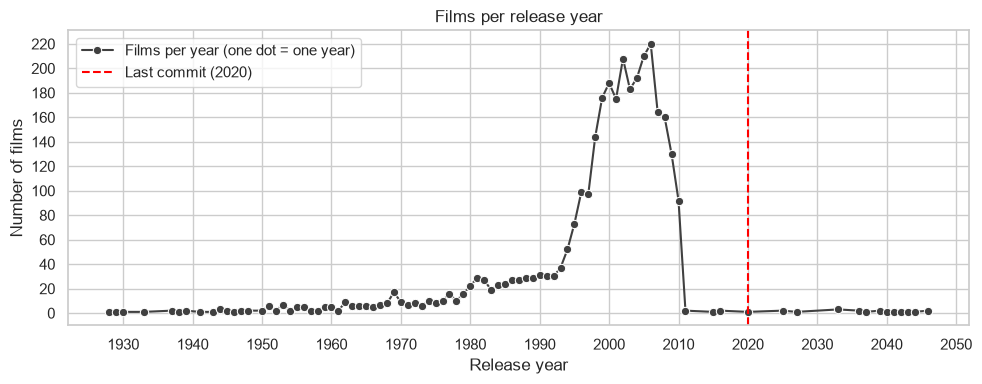

In [81]:
# films per release year (count, sorted by year)
films_per_year = movies["Release Date"].dt.year.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(
    x=films_per_year.index,
    y=films_per_year.values,
    marker="o",
    ax=ax,
    label="Films per year (one dot = one year)",
)
ax.xaxis.set_major_locator(MultipleLocator(10))
ax.yaxis.set_major_locator(MultipleLocator(20))
ax.axvline(2020, color="red", linestyle="--", label="Last commit (2020)")
ax.set_title("Films per release year")
ax.set_xlabel("Release year")
ax.set_ylabel("Number of films")
ax.legend()
plt.tight_layout()
plt.show()

- 19 films have a release date after the last commit date of the dataset.
- Our plot shows that most of the data lies between about 1990 and 2010.
- The number of films released after 2010 is suspiciously low to be representative. This needs looking into.

In [82]:
# list films between 2011 and the last commit
suspicious = by_date.loc[by_date["Release Date"].between("2011-01-01", "2020-06-16")]
display(suspicious)

# check if those movies have values for other columns
display(movies[movies["Release Date"].between("2011-01-01", "2020-06-16")])

,Title,Release Date
26,"20,000 Leagues Under the Sea",2016-12-24
467,Intolerance,2016-09-05
120,The Birth of a Nation,2015-02-08
2967,The Adventures of Tintin: Secret of the Unicorn,2011-12-23
2658,Restless,2011-01-28


,Title,US Gross,Worldwide Gross,US DVD Sales,Production Budget,Release Date,MPAA Rating,Running Time min,Distributor,Source,Major Genre,Creative Type,Director,Rotten Tomatoes Rating,IMDB Rating,IMDB Votes
26,"20,000 Leagues Under the Sea","8,000,000.00","8,000,000.00",NaN,"200,000.00",2016-12-24,NaN,NaN,NaN,Based on Book/Short Story,Adventure,NaN,NaN,NaN,NaN,NaN
120,The Birth of a Nation,"10,000,000.00","11,000,000.00",NaN,"110,000.00",2015-02-08,NaN,NaN,NaN,Based on Book/Short Story,Drama,NaN,NaN,100.00,7.10,"8,901.00"
467,Intolerance,NaN,NaN,NaN,"385,907.00",2016-09-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,96.00,NaN,NaN
2658,Restless,0.00,0.00,NaN,"15,000,000.00",2011-01-28,NaN,NaN,Sony Pictures,NaN,NaN,NaN,NaN,NaN,6.70,300.00
2967,The Adventures of Tintin: Secret of the Unicorn,0.00,0.00,NaN,"130,000,000.00",2011-12-23,NaN,NaN,Paramount Pictures,Based on Comic/Graphic Novel,Adventure,Contemporary Fiction,Steven Spielberg,NaN,NaN,NaN


- All five are real films. The 1915/16 ones have plausible values, while the 2011 films lack gross and ratings (not yet released when the data was collected).
- Checked on IMDb: the three 1915/16 films are dated exactly 100 years too late, while the two 2011 films are correct.
- Since every wrong date is off by exactly 100 years, it looks like a systematic input error rather than random mistakes, so all dates after 2011 are moved back 100 years.

| Film | Dataset date | Real year (IMDb) |
|---|---|---|
| Restless | 2011 | 2011 (real) |
| The Adventures of Tintin | 2011 | 2011 (real, then upcoming) |
| The Birth of a Nation | 2015 | 1915 |
| Intolerance | 2016 | 1916 |
| 20,000 Leagues Under the Sea | 2016 | 1916 |

In [83]:
shifted = movies["Release Date"] > "2011-12-31"
print(f"Films shifted back 100 years: {shifted.sum()}")
movies.loc[shifted, "Release Date"] = movies.loc[
    shifted, "Release Date"
] - pd.DateOffset(years=100)
display(movies["Release Date"].agg(["min", "max"]))

Films shifted back 100 years: 22


min   1915-02-08
max   2011-12-23
Name: Release Date, dtype: datetime64[us]

- 22 films were corrected. The release dates now run from 1915 to 2011.

In [84]:
# how often does each calendar day occur? (all years together)
day_counts = movies["Release Date"].dt.strftime("%m-%d").value_counts()
display(day_counts.head(5))
print(f"Average films per calendar day: {len(movies) / 365:.1f}")

# flag Dec 31 dates so they can be left out of month analyses
movies["date_is_placeholder"] = movies["Release Date"].dt.strftime("%m-%d") == "12-31"

Release Date
12-31    87
12-25    50
12-17    22
11-21    20
12-15    20
Name: count, dtype: int64

Average films per calendar day: 8.8


- 87 films are dated Dec 31, about 10 times the average of about 9 films per day.
- These are probably films where only the year was known. The year is kept, but the new column `date_is_placeholder` lets us leave them out of any month analysis.

### 2.3 Money columns: zeros, identical gross and tiny budgets

In [85]:
money = ["US Gross", "Worldwide Gross", "Production Budget"]
display((movies[money] == 0).sum())  # zeros

same = movies["US Gross"] == movies["Worldwide Gross"]
print(f"US gross == worldwide gross: {same.sum()} films ({same.mean():.0%})")
display(
    movies.loc[same].nlargest(5, "US Gross")[["Title", "US Gross", "Worldwide Gross"]]
)

display(
    movies.nsmallest(5, "Production Budget")[["Title", "Production Budget", "US Gross"]]
)

US Gross             66
Worldwide Gross      47
Production Budget     0
dtype: int64

US gross == worldwide gross: 1272 films (40%)


,Title,US Gross,Worldwide Gross
924,Snow White and the Seven Dwarfs,"184,925,485.00","184,925,485.00"
984,Tootsie,"177,200,000.00","177,200,000.00"
30,3 Men and a Baby,"167,780,960.00","167,780,960.00"
905,The Sting,"159,616,327.00","159,616,327.00"
390,Gremlins,"148,168,459.00","148,168,459.00"


,Title,Production Budget,US Gross
2920,Tarnation,218.00,"592,014.00"
2387,My Date With Drew,"1,100.00","181,041.00"
802,Return to the Land of Wonders,"5,000.00","1,338.00"
6,Following,"6,000.00","44,705.00"
225,Cavite,"7,000.00","70,071.00"


- 66 films have a US Gross of 0, mostly from 2006–2009. These were probably not released or not known yet when the data was collected, so 0 means "unknown", not "earned nothing".
- 1,272 films (40%) have identical US and worldwide gross, including big hits like *Tootsie* and *Gremlins* that surely played abroad. The worldwide figure seems to often just be a copy of the US figure.
- **Decision:** ROI is calculated on `US Gross`, which is consistent for all films.
- The smallest budget, \$218, is real: *Tarnation* (2003) is known for its tiny budget. Small budgets are kept.

In [86]:
# a gross of 0 means "unknown": turn it into a missing value
gross = ["US Gross", "Worldwide Gross"]
movies[gross] = movies[gross].mask(movies[gross] == 0)
movies[gross].isna().sum()

US Gross           73
Worldwide Gross    54
dtype: int64

- The zero values are now missing values (US Gross: 73 missing in total, Worldwide Gross: 54).

## 3. Missing values  [task 3]

### 3.1 Count missing values per column

In [87]:
missing = pd.DataFrame(
    {
        "missing": movies.isna().sum(),
        "percent": (movies.isna().mean() * 100).round(1),
    }
).sort_values("missing", ascending=False)
missing

,missing,percent
US DVD Sales,2637,82.40
Running Time min,1992,62.20
Director,1331,41.60
Rotten Tomatoes Rating,880,27.50
MPAA Rating,605,18.90
Creative Type,446,13.90
Source,365,11.40
Major Genre,275,8.60
Distributor,232,7.20
IMDB Votes,213,6.70


- 1 film has no title. We can't identify it, so it will be dropped.
- US DVD Sales is missing 82.4% of its values, too many to be useful, so the column will be dropped.
- US Gross (73) and Worldwide Gross (54) now include the zeros we turned into missing values in 2.3.
- Running Time (62%) and Director (42%) also have many gaps, but we don't need them for ROI.

### 3.2 Decide: drop, fill or keep (and why)

In [88]:
movies = movies.dropna(subset=["Title"])  # 1 film without a title
movies = movies.drop(columns=["US DVD Sales"])  # 82% missing, not needed
print(f"Rows left: {len(movies)}")

Rows left: 3200


- Dropped the 1 film with no title, because we can't identify it.
- Dropped US DVD Sales: 82% missing, and not needed for ROI.
- Kept the gross values as missing (NaN), not filled. Filling them with a mean would invent box office numbers and skew ROI. pandas skips NaN in mean/median, so those films simply drop out of the ROI analysis.
- Kept Running Time, Director, ratings, MPAA and Creative Type as they are. They have many gaps, but filling text columns with a guess would be wrong. Groupby skips NaN groups by default.

## 4. Merge with genre groups  [task 4]

### 4.1 Merge on Major Genre and check row counts

In [89]:
rows_before = len(movies)
movies = movies.merge(genres, on="Major Genre", how="left")
print(f"Rows before: {rows_before}, after: {len(movies)}")
print(f"Films without a genre group: {movies['Genre group'].isna().sum()}")
movies["Genre group"].value_counts(dropna=False)

Rows before: 3200, after: 3200
Films without a genre group: 275


Genre group
Comedy & music        901
Drama                 789
Action & adventure    730
Thriller & horror     457
NaN                   275
Non-fiction            48
Name: count, dtype: int64

- `how="left"` keeps every film, even those with no genre.
- Rows before and after are the same (3,200), so no film was lost or duplicated.
- 275 films have no genre group. This is the same 275 films that are missing `Major Genre` (see 3.1), so they had nothing to match on.
- Every film that has a genre got a group.
- Biggest groups: Comedy & music (901), Drama (789) and Action & adventure (730). Non-fiction has only 48 films, so its numbers are less reliable.

## 5. New columns  [task 5]

### 5.1 Release year

In [90]:
movies["Release Year"] = movies["Release Date"].dt.year
movies["Decade"] = movies["Release Year"] // 10 * 10  # 1994 -> 1990
movies["Decade"].value_counts().sort_index()

Decade
1910       3
1920       6
1930      15
1940      19
1950      38
1960      71
1970     100
1980     256
1990     769
2000    1829
2010      94
Name: count, dtype: int64

- Added Release Year and Decade so we can group films by time. 
- Most films are from the 1990s (769) and 2000s (1,829). Before 1960 there are fewer than 40 per decade, too few to compare reliably.

### 5.2 ROI (US gross ÷ production budget)

In [91]:
movies["ROI"] = movies["US Gross"] / movies["Production Budget"]
print(f"Films without ROI (gross missing): {movies['ROI'].isna().sum()}")
movies[["Title", "US Gross", "Production Budget", "ROI"]].head()

Films without ROI (gross missing): 74


,Title,US Gross,Production Budget,ROI
0,The Land Girls,"146,083.00","8,000,000.00",0.02
1,"First Love, Last Rites","10,876.00","300,000.00",0.04
2,I Married a Strange Person,"203,134.00","250,000.00",0.81
3,Let's Talk About Sex,"373,615.00","300,000.00",1.25
4,Slam,"1,009,819.00","1,000,000.00",1.01


- ROI = US gross ÷ budget. ROI 1 means the film earned back its budget in the US, and 2 means it earned twice its budget.
- 74 films have no ROI because their gross is missing (from 2.3).
- Note: gross is probably not profit, because marketing costs and the cinemas' share are not mentioned as included.

## 6. Group summaries  [task 6]

### 6.1 ROI by genre group

In [92]:
movies.groupby("Genre group")["ROI"].agg(["count", "median", "mean"]).sort_values(
    "median", ascending=False
)

,count,median,mean
Genre group,,,
Non-fiction,45,1.65,72.49
Thriller & horror,451,1.32,20.35
Comedy & music,889,1.28,3.19
Action & adventure,719,1.12,2.41
Drama,782,0.93,3.34


- Non-fiction has the highest median ROI (1.65) but only 45 films.
- Thriller & horror (1.32) is the best large group.
- Drama is the only group whose median film does not earn back its budget (0.93).
- Means are much higher than medians in every group, so a few huge hits pull the averages up.

### 6.2 ROI by source

In [93]:
movies.groupby("Source")["ROI"].agg(["count", "median"]).sort_values(
    "median", ascending=False
)

,count,median
Source,,
Traditional/Legend/Fairytale,16,1.76
Based on TV,105,1.67
Based on Play,54,1.63
Based on Factual Book/Article,6,1.60
Disney Ride,4,1.46
Based on Short Film,8,1.45
Remake,125,1.30
Spin-Off,8,1.28
Original Screenplay,1514,1.20


- Adaptations of fairytales (1.76), TV shows (1.67) and plays (1.63) have the highest median ROI, but the top groups are small (16, 105 and 54 films).
- Original screenplays, by far the biggest group (1,514 films), sit in the middle (1.20).
- Films based on real life events (0.93) and games (0.81) typically do not earn back their budget.
- Groups with fewer than about 20 films are too small to draw conclusions from.

### 6.3 ROI by decade

In [94]:
movies.groupby("Decade")["ROI"].agg(["count", "median"])

,count,median
Decade,,
1910,2,65.45
1920,4,18.69
1930,14,5.62
1940,18,4.06
1950,36,5.74
1960,63,3.80
1970,95,4.89
1980,255,2.56
1990,768,1.13


- Median ROI falls decade by decade: from about 4-6 before 1980 to 1.13 in the 1990s and 0.94 in the 2000s.
- The early decades have very few films (under 40 each, see 5.1). They are probably the classics that are still remembered, so they look more successful than an average old film was (survivorship bias).
- The 2010 group is only 90 films from 2010-2011, some not finished in cinemas when the data was collected.

## 7. A closer look at one column  [task 7]

### 7.1 Mean vs median

In [95]:
display(movies["ROI"].agg(["mean", "median"]))
movies["ROI"].describe()

mean     7.33
median   1.16
Name: ROI, dtype: float64

count   3,126.00
mean        7.33
std       141.90
min         0.00
25%         0.47
50%         1.16
75%         2.45
max     7,194.59
Name: ROI, dtype: float64

- The mean ROI (7.33) is more than six times the median (1.16).
- The standard deviation (141.9) is huge compared with the median, and the max is 7,195.
- So ROI is strongly right-skewed: a few extreme hits pull the mean up. **The median is the better measure of a "typical" film**, which is why the group summaries use it.
- 25% of films earn less than half their budget back (Q1 = 0.47).
- Comparing two groups: the median Thriller & horror film has an ROI of 1.32, the median drama only 0.93.

### 7.2 Spread and outliers

In [96]:
# IQR rule: values above Q3 + 1.5 * IQR count as outliers
q1, q3 = movies["ROI"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
outliers = movies["ROI"] > upper
print(f"Q1: {q1:.2f}, Q3: {q3:.2f}, upper limit: {upper:.2f}")
print(f"Outliers: {outliers.sum()} films")
movies.nlargest(5, "ROI")[
    ["Title", "Release Year", "Production Budget", "US Gross", "ROI"]
]

Q1: 0.47, Q3: 2.45, upper limit: 5.42
Outliers: 328 films


,Title,Release Year,Production Budget,US Gross,ROI
2526,Paranormal Activity,2009,"15,000.00","107,918,810.00","7,194.59"
2920,Tarnation,2004,218.00,"592,014.00","2,715.66"
244,Deep Throat,1972,"25,000.00","45,000,000.00","1,800.00"
132,The Brothers McMullen,1995,"25,000.00","10,426,506.00",417.06
531,El Mariachi,1993,"7,000.00","2,040,920.00",291.56


- With the IQR rule, 328 films (about 10%) are outliers above an ROI of 5.42.
- The biggest are tiny-budget films that became hits: *Paranormal Activity* (\$15,000 budget, 7,195× ROI), *Tarnation* (\$218) and *Deep Throat*.
- These are real films, not data errors, so they are **kept**. We use the median so they do not dominate the results.

## 8. Charts  [task 8]

### 8.1 Bar chart: median ROI by genre group

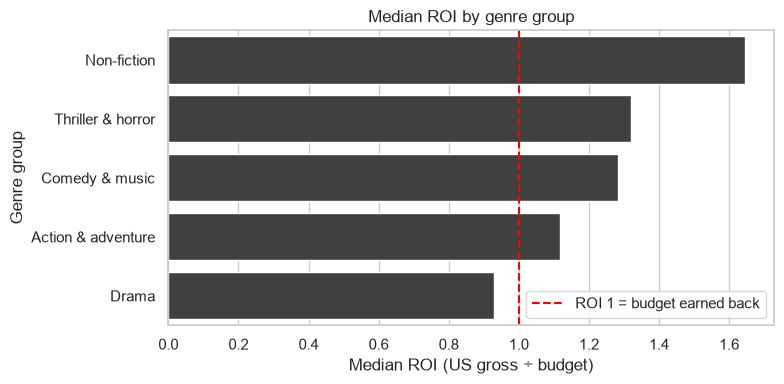

In [97]:
genre_roi = movies.groupby("Genre group")["ROI"].median().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=genre_roi.values, y=genre_roi.index, ax=ax)
ax.axvline(1, color="red", linestyle="--", label="ROI 1 = budget earned back")
ax.set_title("Median ROI by genre group")
ax.set_xlabel("Median ROI (US gross ÷ budget)")
ax.set_ylabel("Genre group")
ax.legend()
plt.tight_layout()
plt.show()

- Thriller & horror and Comedy & music have the highest median ROI among the large groups.
- Drama is the only group below the red line, so the typical drama does not earn back its budget in the US.

### 8.2 Histogram: how ROI is spread

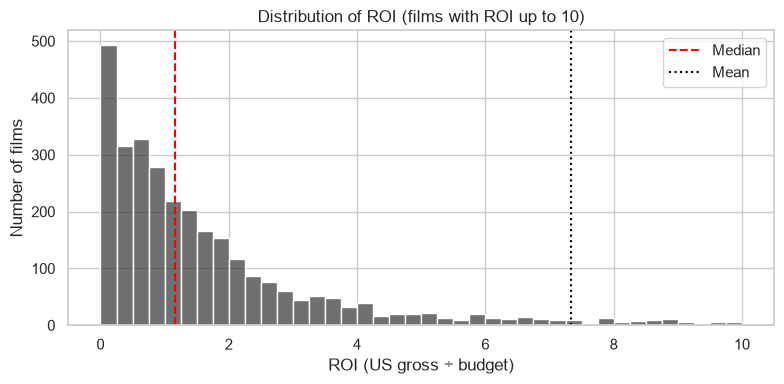

In [98]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(
    data=movies[movies["ROI"] <= 10], x="ROI", bins=40, ax=ax
)  # ROI above 10 left out so the bars are readable
ax.axvline(movies["ROI"].median(), color="red", linestyle="--", label="Median")
ax.axvline(movies["ROI"].mean(), color="black", linestyle=":", label="Mean")
ax.set_title("Distribution of ROI (films with ROI up to 10)")
ax.set_xlabel("ROI (US gross ÷ budget)")
ax.set_ylabel("Number of films")
ax.legend()
plt.tight_layout()
plt.show()

- Most films have an ROI between 0 and 2, and the distribution has a long tail to the right.
- The mean (black line) lies far to the right of the median (red line), which shows the skew from 7.1 in one picture.
- 161 films with ROI above 10 are left out so the bars are readable.

### 8.3 Scatter plot: budget vs US gross

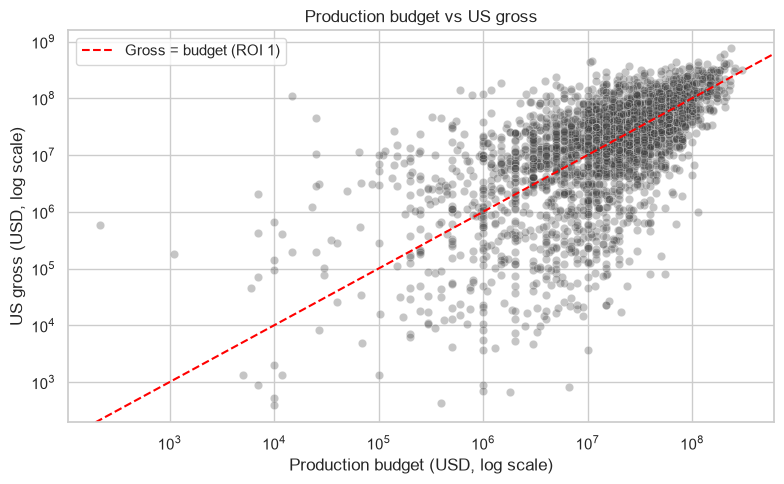

In [99]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=movies, x="Production Budget", y="US Gross", alpha=0.3, ax=ax)
ax.axline(
    (1e6, 1e6), slope=1, color="red", linestyle="--", label="Gross = budget (ROI 1)"
)
ax.set_xscale("log")  # log scale: budgets range from $218 to $300 million
ax.set_yscale("log")
ax.set_title("Production budget vs US gross")
ax.set_xlabel("Production budget (USD, log scale)")
ax.set_ylabel("US gross (USD, log scale)")
ax.legend()
plt.tight_layout()
plt.show()

- Bigger budgets generally bring bigger gross (correlation 0.62), so the dots rise from left to right.
- But many films sit below the red line, where gross is lower than budget. Spending more does not guarantee earning it back.
- The dots far above the line on the left are the cheap films with huge ROI from 7.2.

### 8.4 Box plot: ROI by source (most common sources)

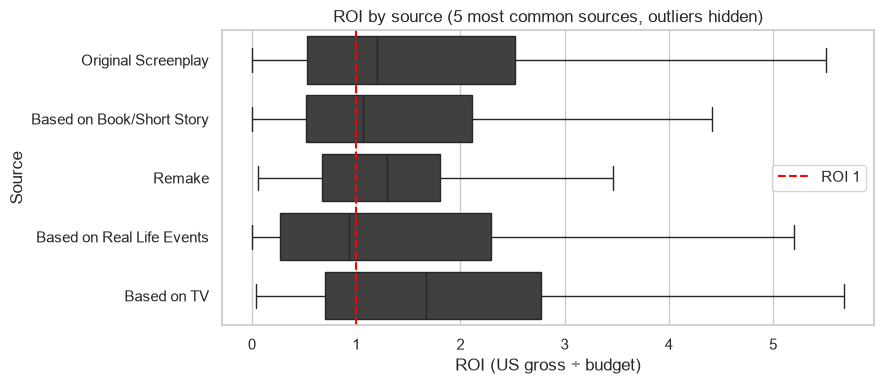

In [100]:
top_sources = movies["Source"].value_counts().head(5).index
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(
    data=movies[movies["Source"].isin(top_sources)],
    x="ROI",
    y="Source",
    showfliers=False,
    ax=ax,  # outliers hidden, see 7.2
)
ax.axvline(1, color="red", linestyle="--", label="ROI 1")
ax.set_title("ROI by source (5 most common sources, outliers hidden)")
ax.set_xlabel("ROI (US gross ÷ budget)")
ax.set_ylabel("Source")
ax.legend()
plt.tight_layout()
plt.show()

- TV adaptations and remakes have the highest medians of the five most common sources.
- Films based on real life events have a median below 1.
- The boxes overlap a lot, so the source alone does not decide whether a film pays off.

## 9. My questions  [task 9]

### Q1 Do bigger budgets give a better ROI?

,count,median,mean
Budget group,,,
Low,765,2.08,24.84
Mid-low,896,1.20,2.20
Mid-high,677,1.06,1.49
High,788,0.96,1.18


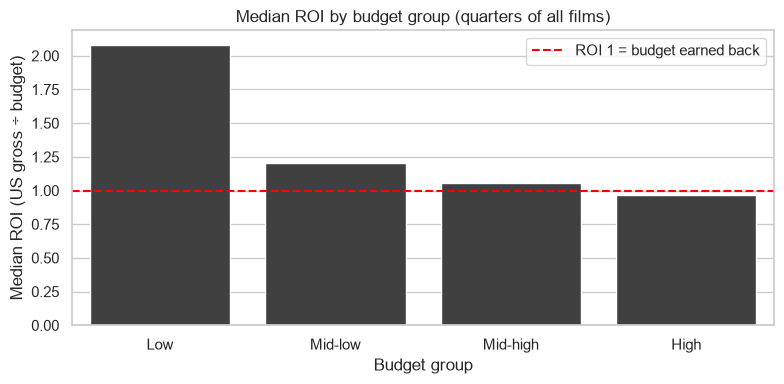

In [101]:
# split films into 4 equally big budget groups
movies["Budget group"] = pd.qcut(
    movies["Production Budget"], 4, labels=["Low", "Mid-low", "Mid-high", "High"]
)
budget_roi = movies.groupby("Budget group", observed=True)["ROI"].agg(
    ["count", "median", "mean"]
)
display(budget_roi)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=budget_roi.index, y=budget_roi["median"], ax=ax)
ax.axhline(1, color="red", linestyle="--", label="ROI 1 = budget earned back")
ax.set_title("Median ROI by budget group (quarters of all films)")
ax.set_xlabel("Budget group")
ax.set_ylabel("Median ROI (US gross ÷ budget)")
ax.legend()
plt.tight_layout()
plt.show()

- **Yes, but the other way round:** the cheapest quarter of films has the best median ROI (2.08), the most expensive quarter the lowest (0.96).
- The typical big-budget film does not earn back its cost in the US alone (worldwide gross is not used, see 2.3).
- Low-budget films are also the riskiest group: the mean (24.8) is far above the median, driven by a few huge hits.
- **Chart:** the bars fall step by step from Low to High budget; only the high-budget bar is below the red line.
- **But see the 1990-2009 check after Q3:** for newer films this difference almost disappears.

### Q2 How many films earn back their budget, per genre group?

Genre group
Thriller & horror    62.10
Comedy & music       59.40
Non-fiction          55.60
Action & adventure   53.50
Drama                47.10
Name: ROI, dtype: float64

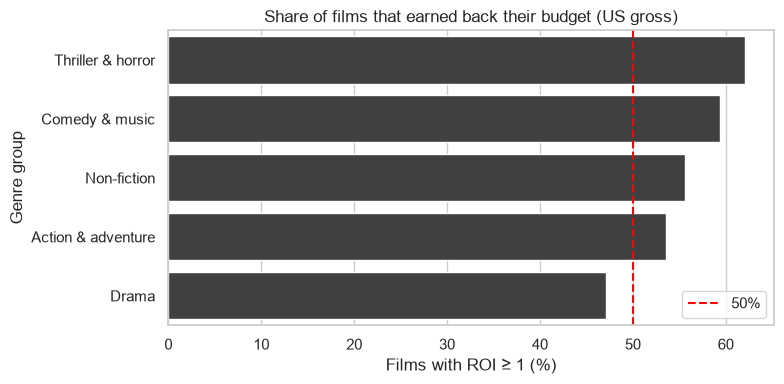

In [102]:
has_roi = movies.dropna(subset=["ROI"])
earned_back = (has_roi["ROI"] >= 1).groupby(has_roi["Genre group"]).mean() * 100
display(earned_back.sort_values(ascending=False).round(1))

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(
    x=earned_back.values,
    y=earned_back.index,
    order=earned_back.sort_values(ascending=False).index,
    ax=ax,
)
ax.axvline(50, color="red", linestyle="--", label="50%")
ax.set_title("Share of films that earned back their budget (US gross)")
ax.set_xlabel("Films with ROI ≥ 1 (%)")
ax.set_ylabel("Genre group")
ax.legend()
plt.tight_layout()
plt.show()

- Thriller & horror films earn back their budget most often (62%), dramas least often (47%).
- Overall, 1,712 of the 3,126 films with an ROI (55%) earned back their budget in the US.
- **Chart:** every group except Drama is above the 50% line.

### Q3 Do higher-rated films (IMDb) give a better ROI?

,count,median
IMDB group,,
under 5,454,0.82
5-6,674,0.93
6-7,955,1.05
7+,855,1.77


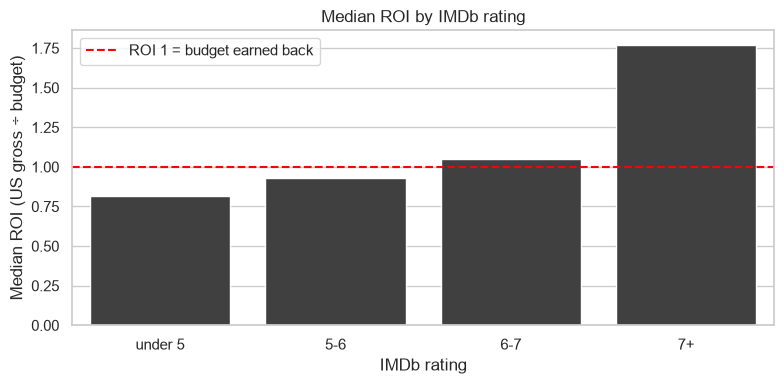

In [103]:
movies["IMDB group"] = pd.cut(
    movies["IMDB Rating"], bins=[0, 5, 6, 7, 10], labels=["under 5", "5-6", "6-7", "7+"]
)
imdb_roi = movies.groupby("IMDB group", observed=True)["ROI"].agg(["count", "median"])
display(imdb_roi)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=imdb_roi.index, y=imdb_roi["median"], ax=ax)
ax.axhline(1, color="red", linestyle="--", label="ROI 1 = budget earned back")
ax.set_title("Median ROI by IMDb rating")
ax.set_xlabel("IMDb rating")
ax.set_ylabel("Median ROI (US gross ÷ budget)")
ax.legend()
plt.tight_layout()
plt.show()

- **Yes:** median ROI rises with the IMDb rating, from 0.82 (under 5) to 1.77 (7+).
- Caution: IMDb ratings are given by today's audience, often long after release. A film that made money is seen by more people, so the rating may partly be a *result* of success, not a cause.
- **Chart:** the bars rise with the rating; only films rated 7+ clearly clear the red line.

### Check: do the answers hold for 1990-2009 only?
Old films may look too good: their gross can include re-releases decades later, and their budgets are in old dollars. Films from 1990-2009 had little time for re-releases and had finished their cinema run, so I repeat Q1-Q3 for them only.

In [104]:
recent = movies[movies["Release Year"].between(1990, 2009)].dropna(subset=["ROI"])
print(f"Films 1990-2009 with an ROI: {len(recent)}")

display(recent.groupby("Budget group", observed=True)["ROI"].median().round(2))
display(((recent["ROI"] >= 1).groupby(recent["Genre group"]).mean() * 100).round(1))
display(recent.groupby("IMDB group", observed=True)["ROI"].median().round(2))

Films 1990-2009 with an ROI: 2549


Budget group
Low        1.01
Mid-low    1.06
Mid-high   1.02
High       0.96
Name: ROI, dtype: float64

Genre group
Action & adventure   48.50
Comedy & music       56.60
Drama                44.20
Non-fiction          57.10
Thriller & horror    58.40
Name: ROI, dtype: float64

IMDB group
under 5   0.78
5-6       0.84
6-7       0.98
7+        1.40
Name: ROI, dtype: float64

- **Q1 does not hold:** for 1990-2009 the budget groups are almost equal (median ROI 1.01 for low vs 0.96 for high budgets). The big difference in Q1 came mostly from old films with small budgets in old dollars and lifetime gross.
- **Q2 holds:** Thriller & horror still earns back its budget most often (58%), drama least often (44%).
- **Q3 holds, a bit weaker:** median ROI 1.40 for films rated 7+ vs 0.78 for films under 5.
- So I only trust the genre and rating findings.

## 10. Data note  [task 10]

### 10.1 Source

- **Who and when:** the data comes from **vega-datasets**, a collection of teaching data sets on GitHub (`data/movies.json`, here as `movies.csv`). The file was last changed on 16 June 2020. The release dates and the zero gross values suggest the figures were collected around 2010-2011.
- **Original source unknown:** the vega-datasets description of *movies* names **no original source**. It only says the data has known quality problems and is meant for teaching data cleaning. So I do not know who collected the box office and budget figures, when, or how.
- Genre groups: `genre_groups.csv`, a small lookup table made for this project that maps Major Genre to 5 groups.
- The data does not say which currency is used or whether the money is adjusted for inflation. I assume US dollars, probably not adjusted (see 10.3).

### 10.2 Spot-checks against other sources

- Five suspicious release dates (2011-2016) were checked by hand on IMDb (section 2.2). Three of them were 100 years too late, which revealed a systematic error that affected 22 films.
- *Tarnation*'s \$218 budget (2.3) matches what is publicly known about the film, so tiny budgets were kept.
- 40% of films have exactly the same US and worldwide gross, including big international hits. This cannot be right, so worldwide gross was not used.

### 10.3 Limitations

- **Inflation probably not adjusted:** the data does not say, but the figures look like nominal dollars (*Snow White*'s \$185M is far below its value in today's money). ROI is a ratio, so inflation cancels out when budget and gross are from the same years, but not when gross includes re-releases decades later.
- **US gross only:** foreign income is missing, which undervalues films that did well abroad.
- **Gross is not profit:** marketing costs and the cinemas' share are not included.
- **Missing values:** 74 films have no ROI, 275 have no genre, many have no running time or director.
- **Selection:** older films in the data seem to be mostly well-known ones (fewer than 40 per decade before 1960), which may make the early decades look better than they were.
- **Ratings are from today**, not from the release year.
- **Who/what is not in the data:** films that never had a US cinema release, most films from before 1980 (only a few, probably well-known ones, are included), and anything about marketing costs or streaming/DVD income (DVD sales were 82% empty).
- **Time since release:** older films have had longer to collect IMDb ratings and votes, and their gross may include re-releases (e.g. *Snow White* 1937). The newest films (2010-2011) may not have finished their cinema run when the data was collected. Both could make old films look better than new ones, but the data does not let us check this.
- **Lifetime or first-run gross?** The data does not say. It is probably the lifetime total including re-releases: *Snow White* (1937) shows \$184.9 million in US gross, far more than a 1937 first run could earn with tickets at about 25 cents.

### 10.4 A claim I would not dare to make

- *"Making a horror film with a small budget will give you a good return."*
- Thrillers and horror films earned back their budget more often than other genres in this data, but the budget effect does not hold for 1990-2009 (see the check after Q3), the data only covers the US box office without marketing costs, and extreme hits like *Paranormal Activity* are rare exceptions. It shows a pattern in the past, not a cause or a guarantee.

## Conclusion

**What makes a film a good investment?** Measured as US gross ÷ production budget:

- **Genre matters.** Thriller & horror earns back its budget most often (62%, 58% for 1990-2009), drama least often (47%, 44%).
- **Good ratings go with good returns** (median ROI 1.77 for IMDb 7+ vs 0.82 under 5; 1.40 vs 0.78 for 1990-2009), but successful films may also get more viewers and ratings.
- **Adaptations of TV shows and plays** do better than original screenplays and films based on real events.
- **Budget size: not proven.** Over all years cheap films look much better (2.08 vs 0.96), but for 1990-2009 the difference almost disappears (1.01 vs 0.96). The effect comes mostly from old films with re-releases and old-dollar budgets.
- **ROI is very skewed:** a few extreme hits (e.g. *Paranormal Activity*) make the mean misleading, so the median was used throughout.

**Overall:** these results only cover the US box office, without inflation adjustment or marketing costs, and the source of the data is unknown (see section 10). The dataset is useful for practising data cleaning and analysis, but it has too little and too uncertain information to base real investment decisions on. A real analysis would need documented, inflation-adjusted figures including worldwide income and marketing costs.